# 02 · Feature Building

**Goal:** pair every time entry with every matter it could belong to, and describe each pair with clues a rule or model can use to pick the right one.

**Output:** the pairs table, one row per (entry, candidate matter): 4,000 entries × 103 matters = 412,000 rows. For one entry it looks like this:

| entry | candidate matter | typed CMID is this matter? | client score | key term found? | task cue fits? | open on work date? | billed recently? | right answer? |
|---|---|---|---|---|---|---|---|---|
| T-00017 | 6103.004 2026 Annual Meeting | no | 100 | yes | yes | yes | yes | **yes** |
| T-00017 | 6103.001 General Corporate | no | 100 | no | no | yes | yes | no |
| T-00017 | 9028.001 General Corporate | no | 39 | no | no | yes | no | no |

**Kinds of clues**
- **Typed fields:** the CMID (cleaned up), and fuzzy scores for the typed client and matter names (notebook 01)
- **Narrative:** key terms that name a matter, task cues that hint at the type of work, client names, and contact names
- **Dates:** whether the matter was open on the day the work was done
- **Timekeeper history:** whether this person billed the matter recently

**Questions**
1. Do the cleanup steps recover the right values?
2. Which clues point to the right matter, and which only narrow things down?
3. Do the narrative clues hold up on VAL?

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rapidfuzz import fuzz

sys.path.insert(0, "../src")
from clean import normalize, is_ditto, clean_cmid, cmid_status, clean_entries, flip_cmid, cmid_similarity
from fuzzy import client_name_table, matter_name_table, match, add_name_scores
from cues import cue_table, check_cue_types, CUE_SOURCES
from features import (make_pairs, add_cmid_features, keyterm_table, client_mention_table, contact_table,
                      window_score, phrase_scores, add_text_features, add_date_features, add_history_features,
                      add_gaps, feature_groups, build_pairs)

In [2]:
DATA_PATH = Path("../data/synthetic_time_entries_v3.xlsx")
RESULTS_DIR = Path("../results")
TUNE, CHECK = "TRAIN", "VAL"

ENTRY_COLS = {"Time ID": "entry_id", "TK ID": "tk_id", "Source Format": "source_format", "Date": "work_date",
              "CMID": "cmid", "Client": "client", "Matter": "matter", "Narrative": "narrative"}
MATTER_COLS = {"CMID": "cmid", "Client": "client", "Matter": "matter", "Matter Type": "matter_type",
               "Status": "status", "Open Date": "open_date", "Close Date": "close_date"}
HISTORY_COLS = {"TK ID": "tk_id", "CMID": "cmid", "Hours (04/01-06/30/2026)": "hours"}
HISTORY_END = pd.Timestamp("2026-06-30")

PHRASE_MIN = 90   # a phrase counts as found in the narrative at this score or higher (section 6)

## 2. Load data

The answer key (`KEY:` columns) is split off right away and only comes back at the end as labels, so the clues only use what a firm would actually receive.

In [3]:
sheets = pd.read_excel(DATA_PATH, sheet_name=None, dtype=str)
raw, matter_master = sheets["Time Entries"], sheets["Matter Master"]

entries = raw[list(ENTRY_COLS)].rename(columns=ENTRY_COLS)
matters = matter_master[list(MATTER_COLS)].rename(columns=MATTER_COLS)
history = sheets["TK Matter History"][list(HISTORY_COLS)].rename(columns=HISTORY_COLS)
answers = (raw[["Time ID"] + [c for c in raw.columns if c.startswith("KEY: ")]]
           .rename(columns=lambda c: "entry_id" if c == "Time ID" else c.replace("KEY: ", "key_").lower().replace(" ", "_"))
           .rename(columns={"key_split": "split"}))
valid_cmids = set(matters["cmid"])

assert set(answers["split"]) == {"TRAIN", "VAL", "TEST"}
assert not any(c.startswith("KEY") for c in entries.columns)
assert pd.to_datetime(entries["work_date"]).min() > HISTORY_END
print(f"{len(entries):,} entries | {len(matters)} matters | {matters['matter_type'].nunique()} matter types")

4,000 entries | 103 matters | 18 matter types


## 3. Cleaning up the typed fields

Three things are fixed before matching:
- **Ditto marks:** handwritten sheets use `"`, "ditto", "same", or "↓" to mean "same client as above".
- **Client and matter in one field:** "Meridian / sec reporting", "Juniper Peak-Fund II".
- **CMIDs written in the narrative:** emails leave the CMID field blank but sometimes put it in the body ("Northgate Bank / 7215/003: ...").

In [4]:
fields = clean_entries(entries)
check = entries.join(fields).merge(answers[["entry_id", "split", "key_true_client", "key_true_cmid"]], on="entry_id")
train = check[check["split"] == TUNE].copy()
client_names = client_name_table(matter_master)


def points_to(typed, true_client):
    top = match(typed, client_names, k=1) if isinstance(typed, str) and not is_ditto(typed) else []
    return bool(top) and top[0][0] == true_client


# Ditto: is the previous row by the same timekeeper the right client?
check["prev_client"] = check.groupby("tk_id")["client"].shift()
dittos = check[(check["split"] == TUNE) & check["client"].map(is_ditto)]
prev_right = np.mean([points_to(p, t) for p, t in zip(dittos["prev_client"], dittos["key_true_client"])])

# One field: does matching only the client part pick the true client more often?
one_field = train[train["client_had_matter"] == 1]
whole = np.mean([points_to(c, t) for c, t in zip(one_field["client"], one_field["key_true_client"])])
part = np.mean([points_to(c, t) for c, t in zip(one_field["typed_client"], one_field["key_true_client"])])

# CMID in the narrative
in_text = train[train["cmid_from_text"] == 1]
found = in_text["typed_cmid"].map(clean_cmid)

print(f"Ditto marks: {len(dittos)} | previous row by the same timekeeper has the true client: {prev_right:.0%}")
print(f"One-field clients: {len(one_field)} | true client from the whole field: {whole:.0%}, from the client part: {part:.0%}")
print(f"CMIDs found in narratives: {len(in_text)} | equal to the true CMID: {(found == in_text['key_true_cmid']).mean():.0%} | "
      f"not in Matter Master: {(~found.isin(valid_cmids)).mean():.0%}")
one_field[["client", "typed_client", "typed_matter", "key_true_client"]].head()

Ditto marks: 19 | previous row by the same timekeeper has the true client: 16%
One-field clients: 52 | true client from the whole field: 92%, from the client part: 98%
CMIDs found in narratives: 16 | equal to the true CMID: 44% | not in Matter Master: 56%


,client,typed_client,typed_matter,key_true_client
15,Maridian Therapevtics-sec,Maridian Therapevtics,sec,Meridian Therapeutics
19,Meridian / sec reporting,Meridian,sec reporting,Meridian Therapeutics
262,Northgate Capital Partners / Acq of Summit Ridge,Northgate Capital Partners,Acq of Summit Ridge,Northgate Capital Partners
294,Meridian Tx / sec reporting,Meridian Tx,sec reporting,Meridian Therapeutics
406,Northgate – Asterion,Northgate,Asterion,Northgate Bank


- **Ditto marks** are treated as a blank client. The row above usually isn't the line above on the paper sheet, so it has the true client only about 1 time in 6.
- **One-field clients** are split at the first "/" or "-". No client name in Matter Master contains one, and the client part picks the true client 98% of the time (92% for the whole field). The right-hand part becomes the typed matter.
- **CMIDs in emails** are rare (16 on TRAIN). Every one that exists in Matter Master is right, and the rest aren't in Matter Master yet, which is a `NO_MATCH` hint.

## 4. The pairs table

Every entry is paired with every matter, so the right matter is always one of the candidates. Each section below adds columns.

In [5]:
pairs = make_pairs(entries, matters)
print(f"{len(entries):,} entries x {len(matters)} matters = {len(pairs):,} pairs")

4,000 entries x 103 matters = 412,000 pairs


## 5. CMID

Typed CMIDs have three kinds of problems:
- **Format:** `3012004`, `3012/004`, `3012.4`, fixed with a pattern
- **OCR letters:** `61D3.004`, `6103.O05`, `BO12.001`, where handwriting or a scan swapped a letter for a digit
- **Doesn't exist:** the cleaned CMID isn't in Matter Master. That's either a typo of a real CMID or a matter that hasn't been opened yet.

In [6]:
pairs = add_cmid_features(pairs, valid_cmids)

per_entry = pairs.drop_duplicates("entry_id").merge(answers, on="entry_id")
ocr_fixed = per_entry["cmid_clean"].notna() & ~per_entry["typed_cmid"].fillna("").str.fullmatch(r"[\d\s.\-/,]*")
print("Entries by CMID status:", per_entry["cmid_status"].value_counts().to_dict())
print("Fixed by reading OCR letters as digits:", ocr_fixed.sum())
per_entry.loc[ocr_fixed, ["typed_cmid", "cmid_clean"]].head(6)

Entries by CMID status: {'missing': 2027, 'valid': 1411, 'reformatted': 391, 'invalid': 171}
Fixed by reading OCR letters as digits: 131


,typed_cmid,cmid_clean
12,bID3 o04,6103.004
46,"3|Z0,O0I",3120.001
70,72ZZ.00Z,7222.002
86,61D3.004,6103.004
87,6103.O05,6103.005
129,34Ss.D02,3455.002


In [7]:
bad = per_entry[(per_entry["cmid_status"] == "invalid") & (per_entry["split"] == TUNE)].copy()
bad["client_number_exists"] = bad["cmid_client_known"] == 1
bad["closest"] = bad["cmid_flipped"].fillna(bad["cmid_clean"].map(lambda c: max(valid_cmids, key=lambda v: (cmid_similarity(c, v), v))))
bad["closest_is_true"] = bad["closest"] == bad["key_true_cmid"]
bad.groupby(["key_expected_action", "client_number_exists"]).agg(entries=("entry_id", "size"), closest_is_true=("closest_is_true", "mean")).round(2)

entries  closest_is_true
key_expected_action client_number_exists                          
AUTO_MATCH          False                       9             1.00
                    True                       52             0.63
NO_MATCH            False                      27             0.00
                    True                       30             0.00

- The OCR step fixes all 131 CMIDs with letters in them.
- **Typos** (expected `AUTO_MATCH`): the closest real CMID is the true matter about 70% of the time.
- **Not open yet** (expected `NO_MATCH`): about half have a real client number (`9140.009`, a new matter at a known client), so the CMID alone can't tell them apart from typos. The other clues have to decide.

## 6. Names

Fuzzy scores for the typed client against each candidate's client, and the typed matter against each candidate's matter name or codename (0 when blank). Notebook 01's picks are used, plus their runner-ups.

In [8]:
choice = json.loads((RESULTS_DIR / "01_scorer_choice.json").read_text())
SCORERS = list(dict.fromkeys([choice["client_scorer"], choice["matter_scorer"], choice["client_runner_up"], choice["matter_runner_up"]]))
CLIENT_COL, MATTER_COL = f"client_{choice['client_scorer'].lower()}", f"matter_{choice['matter_scorer'].lower()}"

matter_names = matter_name_table(matter_master)
pairs = add_name_scores(pairs, client_names, matter_names, SCORERS)
print("Scorers:", SCORERS)

Scorers: ['ratio', 'token_sort_ratio', 'token_set_ratio']


## 7. Narrative

The narrative is the one field that's always filled in. Four kinds of phrases are searched for:
- **Key terms** from Matter Master name a matter ("Project Wren", "Summit Ridge"). A term listed for several matters ("Fund II") only narrows things down.
- **Task cues** hint at the type of work ("capital call" means fund administration). They come from public lists: UTBMS billing task codes, SEC form names, standard deal documents, and NALP recruiting terms.
- **Client names** ("[Pelican Row Holdings] ...", common in emails)
- **Contacts:** Matter Master lists "P. Kaur", and narratives say "call w/ Kaur", so surnames are matched.

Phrases are compared against whole words, so "tern" doesn't match inside "internal" but typos still score high. Numbers, roman numerals, and single letters have to match exactly, since Fund II and Fund III are different matters.

In [9]:
demo = [("tern", "draft internal memo"), ("capital call", "prep capial call notices"),
        ("fund ii", "track fund iii investor subscriptions"), ("kaur", "correspondence with kaur re indemnities")]
pd.DataFrame([{"phrase": p, "narrative": t, "partial_ratio": round(fuzz.partial_ratio(p, t)),
               "window_score": round(window_score(p, t))} for p, t in demo])

,phrase,narrative,partial_ratio,window_score
0,tern,draft internal memo,100,67
1,capital call,prep capial call notices,92,96
2,fund ii,track fund iii investor subscriptions,100,0
3,kaur,correspondence with kaur re indemnities,100,100


In [10]:
keyterms = keyterm_table(matter_master)
cues = cue_table()
client_mentions = client_mention_table(matter_master)
contacts = contact_table(matter_master)
check_cue_types(cues, matters["matter_type"])

print(f"Key terms: {len(keyterms)} for {keyterms['cmid'].nunique()} matters ({keyterms['shared'].sum()} shared by 2+ matters)")
print(f"Task cues: {cues['cue_norm'].nunique()} for {cues['matter_type'].nunique()} matter types")
print(f"Client names: {len(client_mentions)} | contact surnames: {contacts['surname'].nunique()}")
cues.drop_duplicates("cue_norm")["source"].value_counts().rename("cues").to_frame().assign(source=lambda d: d.index.map(CUE_SOURCES))

Key terms: 133 for 66 matters (24 shared by 2+ matters)
Task cues: 205 for 18 matter types
Client names: 107 | contact surnames: 61


,cues,source
source,,
DOCS,96,Standard transaction document names
UTBMS_MA,45,ABA/LOC Mergers & Acquisitions UTBMS code set ...
FIRM,25,Common law-firm internal work and wording (to ...
SEC,19,SEC form and filing names (EDGAR)
NVCA,13,NVCA model venture capital financing documents
NALP,7,NALP (National Association for Law Placement) ...


### Choosing the cutoff

Every key term and cue is scored against every TRAIN narrative. A match is **right** if the phrase belongs to the entry's true matter (key terms) or its matter type (cues).

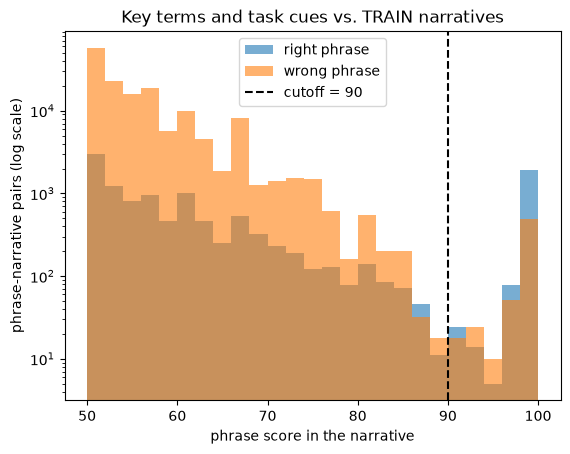

In [11]:
type_of = matters.set_index("cmid")["matter_type"]
labeled = train[train["key_true_cmid"] != "NONE"]
true_cmid = dict(zip(labeled["narrative"].map(lambda t: normalize(t, drop_suffixes=False)), labeled["key_true_cmid"]))
scores = phrase_scores(list(keyterms["term_norm"]) + list(cues["cue_norm"]), true_cmid.keys())

long = scores.stack().rename("score").reset_index().set_axis(["text", "phrase", "score"], axis=1).query("score >= 50")
long["true_cmid"] = long["text"].map(true_cmid)
term_owner = keyterms.groupby("term_norm")["cmid"].agg(set)
cue_types = cues.groupby("cue_norm")["matter_type"].agg(set)
long["right"] = [c in term_owner.get(p, set()) or type_of[c] in cue_types.get(p, set()) for p, c in zip(long["phrase"], long["true_cmid"])]

bins = np.linspace(50, 100, 26)
plt.hist(long.loc[long["right"], "score"], bins=bins, alpha=0.6, label="right phrase")
plt.hist(long.loc[~long["right"], "score"], bins=bins, alpha=0.6, label="wrong phrase")
plt.axvline(PHRASE_MIN, color="black", linestyle="--", label=f"cutoff = {PHRASE_MIN}")
plt.yscale("log")
plt.xlabel("phrase score in the narrative")
plt.ylabel("phrase-narrative pairs (log scale)")
plt.title("Key terms and task cues vs. TRAIN narratives")
plt.legend()
plt.show()

- Right matches cluster at 100, and typos of real phrases ("capial call") land between 90 and 99. Look-alikes ("nda" vs. "snda") fall below 90, so the cutoff stays at 90.
- Some wrong matches score 100: the word is really there but means other work, like "closing" in the stock phrase "in preparation for closing", or "tax". A cutoff can't fix those, so those cues are noted for review by someone who has billed time.

In [12]:
pairs = add_text_features(pairs, keyterms, cues, client_mentions, contacts, PHRASE_MIN)

## 8. Dates and timekeeper history

- **Dates:** time can't be billed to a matter before it opened or after it closed.
- **History:** hours each timekeeper billed to each matter from April 1 to June 30, 2026. Every entry is dated after that, so history never includes the entries it's used to predict. Matters opened after June can't have history yet, which `opened_after_history` marks.

In [13]:
pairs = add_date_features(pairs, HISTORY_END)
pairs = add_history_features(pairs, history)

typed_rows = pairs[pairs["is_typed_cmid"] == 1].merge(answers, on="entry_id").query("split == @TUNE")
typed_rows.groupby("key_entry_category")["not_open"].mean().round(2).rename("typed matter not open").to_frame()

,typed matter not open
key_entry_category,
CLEAN,0.0
CLOSED_OR_NOT_OPEN,1.0
MESSY,0.0
SPLIT_NAMED,0.0
SPLIT_UNNAMED,0.0
WRONG_CMID_SILENT,0.0
WRONG_CMID_TEXT,0.0


- Only `CLOSED_OR_NOT_OPEN` entries have a typed matter that wasn't open on the work date, so `not_open` is a clean signal.

## 9. Put it together

`build_pairs` in `src/features.py` runs every step above in one call, which is what notebook 03 and the app use. The check makes sure it matches the step-by-step table.

Each `_gap` column is a candidate's value minus the best value in its entry (0 = tied for best), so a model can compare candidates within an entry.

In [14]:
GAP_COLS = [CLIENT_COL, MATTER_COL, "keyterm_score", "cue_share", "client_in_text", "history_share", "cmid_similarity"]
pairs = add_gaps(pairs, GAP_COLS).sort_values(["entry_id", "cmid"]).reset_index(drop=True)

rebuilt = build_pairs(entries, matters, history, client_names, matter_names, keyterms, cues, client_mentions,
                      contacts, SCORERS, PHRASE_MIN, GAP_COLS, HISTORY_END)
pd.testing.assert_frame_equal(rebuilt, pairs)

FEATURES = feature_groups(SCORERS, GAP_COLS)
FEATURE_COLS = [c for cols in FEATURES.values() for c in cols]
print(f"{len(FEATURE_COLS)} features:", {group: len(cols) for group, cols in FEATURES.items()})

46 features: {'typed_fields': 9, 'cmid': 6, 'names': 6, 'narrative': 12, 'dates': 2, 'history': 4, 'gaps': 7}


### Labels

A candidate is a true matter if it's the entry's True CMID or Secondary CMID (the second matter of a split). `NO_MATCH` entries have no true matter.

In [15]:
pairs = pairs.merge(answers, on="entry_id", how="left")
pairs["is_true_matter"] = [int(c in (t, s)) for c, t, s in zip(pairs["cmid"], pairs["key_true_cmid"], pairs["key_secondary_cmid"])]

expected = pairs.groupby("entry_id")["key_expected_action"].first().map({"SPLIT_ENTRY": 2, "NO_MATCH": 0}).fillna(1)
assert (pairs.groupby("entry_id")["is_true_matter"].sum() == expected).all()
print(f"{len(pairs):,} pairs | {pairs['is_true_matter'].sum():,} true matters")

412,000 pairs | 4,001 true matters


## 10. Which clues point to the right matter? (TRAIN)

For each entry, a clue "points to" the candidate(s) with its highest value.
- **speaks:** share of entries where the clue points anywhere
- **right alone:** when it speaks, share where it points only to the true matter

Only entries that resolve to one matter are counted.

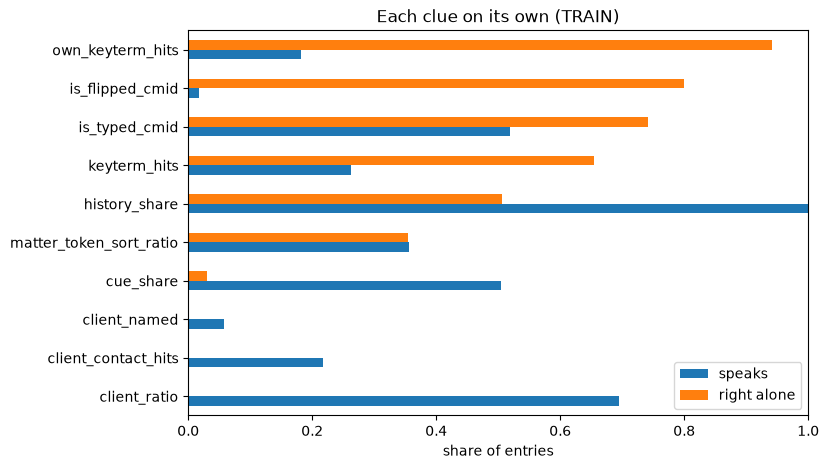

,speaks,right alone
is_typed_cmid,0.52,0.74
own_keyterm_hits,0.18,0.94
is_flipped_cmid,0.02,0.80
keyterm_hits,0.26,0.65
matter_token_sort_ratio,0.36,0.35
history_share,1.00,0.51
cue_share,0.51,0.03
client_ratio,0.69,0.00
client_contact_hits,0.22,0.00
client_named,0.06,0.00


In [16]:
def clue_check(df, clues):
    rows = {}
    for clue in clues:
        best = df.groupby("entry_id")[clue].transform("max")
        points = (df[clue] == best) & (best > 0)
        n_points = points.groupby(df["entry_id"]).sum()
        hits_true = (points & (df["is_true_matter"] == 1)).groupby(df["entry_id"]).any()
        speaks = n_points > 0
        rows[clue] = {"speaks": speaks.mean(), "right alone": (hits_true & (n_points == 1))[speaks].mean()}
    return pd.DataFrame(rows).T


one_matter = pairs["key_expected_action"].isin(["AUTO_MATCH", "FLAG_MISMATCH"])
pairs["client_named"] = (pairs["client_in_text"] >= PHRASE_MIN).astype(int)
CLUES = ["is_typed_cmid", "own_keyterm_hits", "is_flipped_cmid", "keyterm_hits", MATTER_COL, "history_share",
         "cue_share", CLIENT_COL, "client_contact_hits", "client_named"]

clues_train = clue_check(pairs[one_matter & (pairs["split"] == TUNE)], CLUES)
ax = clues_train.sort_values("right alone").plot.barh(figsize=(8, 5), xlim=(0, 1), title="Each clue on its own (TRAIN)")
ax.set_xlabel("share of entries")
plt.show()
clues_train.round(2)

- **The typed CMID** speaks on about half of entries and is right alone about three quarters of the time. Its misses are wrong CMIDs and splits.
- **Key terms listed for one matter** rarely speak but are right alone 94% of the time.
- **Client names, contacts, and task cues** point to every matter of one client, or every matter of one type, so they narrow but almost never decide.
- **History:** the most-billed matter is right about half the time, which helps break ties.
- No single clue is enough, which is why notebook 03 combines them, starting from the client.

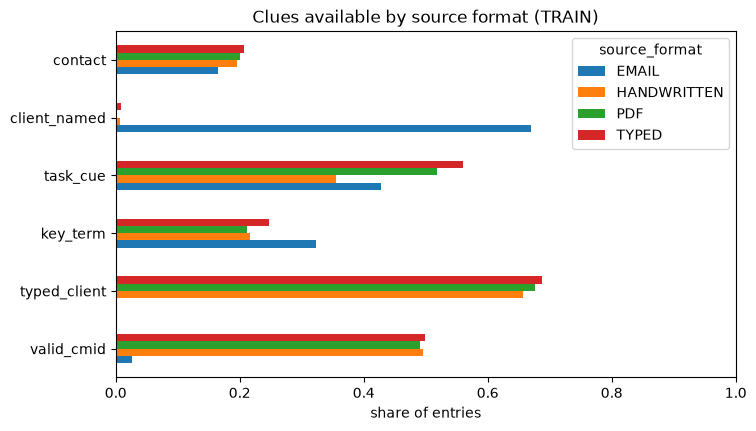

In [17]:
per_entry = pairs[pairs["split"] == TUNE].groupby("entry_id").agg(
    source_format=("source_format", "first"),
    valid_cmid=("cmid_valid", "max"),
    typed_client=(CLIENT_COL, lambda s: s.max() >= 80),
    key_term=("keyterm_hits", lambda s: s.max() > 0),
    task_cue=("cue_hits", lambda s: s.max() > 0),
    client_named=("client_named", "max"),
    contact=("client_contact_hits", lambda s: s.max() > 0))

ax = per_entry.groupby("source_format").mean().T.plot.barh(figsize=(8, 4.5), xlim=(0, 1), title="Clues available by source format (TRAIN)")
ax.set_xlabel("share of entries")
plt.show()

- Typed, PDF, and handwritten entries look alike: about half have a valid CMID and two thirds a typed client.
- Emails have almost no typed fields, but two thirds name the client in the body, so the narrative clues carry them.

## 11. Two cases left for the model

**Unnamed splits:** the narrative mentions other work ("call re unrelated clsg") without naming the matter.

In [18]:
first_rows = pairs[pairs["split"] == TUNE].drop_duplicates("entry_id")
group = np.select([first_rows["key_entry_category"] == "SPLIT_UNNAMED", first_rows["key_entry_category"] == "SPLIT_NAMED"],
                  ["unnamed split", "named split"], "not a split")
first_rows.groupby(group).agg(entries=("entry_id", "size"),
                              names_a_matter=("n_matters_named", lambda s: (s >= 1).mean()),
                              two_plus_parts=("n_parts", lambda s: (s >= 2).mean()),
                              two_plus_types=("n_types_cued", lambda s: (s >= 2).mean())).round(2)

,entries,names_a_matter,two_plus_parts,two_plus_types
named split,77,0.57,0.95,0.57
not a split,2628,0.16,0.37,0.23
unnamed split,97,0.10,1.00,0.26


- Every unnamed split has two or more parts, but so do 37% of ordinary entries, about 10 times as many. A "two parts means split" rule would mostly split entries that aren't splits, so these are left to the classifier.

**Acronyms:** clients typed as initials ("PRH", "NGB") that aren't listed aliases.

In [19]:
acronyms = first_rows[first_rows["key_client_surface"] == "UNLISTED_ACRONYM"]
other = pairs[pairs["entry_id"].isin(acronyms["entry_id"])].groupby("entry_id")["client_contact_hits"].max() > 0
print(f"{len(acronyms)} of {len(first_rows)} TRAIN entries ({len(acronyms) / len(first_rows):.1%}) | client contact named: {other.mean():.0%}")

86 of 2802 TRAIN entries (3.1%) | client contact named: 29%


- Acronyms are about 3% of entries, and about 3 in 10 get the client from a contact instead. Initials would also collide ("HB" fits both Harborlight Bio and Harborline Biosciences), so they stay a known limitation for now.

## 12. Check on VAL (once)

The cutoff was chosen on TRAIN, and VAL uses phrasings not seen in TRAIN.

In [20]:
TEXT_CLUES = ["own_keyterm_hits", "keyterm_hits", "cue_share", "client_named"]
pd.concat({split: clue_check(pairs[one_matter & (pairs["split"] == split)], TEXT_CLUES) for split in [TUNE, CHECK]}, axis=1).round(2)

TRAIN                VAL            
                 speaks right alone speaks right alone
own_keyterm_hits   0.18        0.94   0.19        0.92
keyterm_hits       0.26        0.65   0.26        0.68
cue_share          0.51        0.03   0.55        0.02
client_named       0.06        0.00   0.06        0.00

- Key terms hold steady (right alone 94% on TRAIN, 92% on VAL), and coverage is about the same on both splits.

## 13. Save

The pairs table is saved as parquet. At about 400,000 rows it's much smaller than a CSV, and it keeps column types, so CMIDs like `1111.010` stay text.

In [21]:
keep = (["entry_id", "tk_id", "source_format", "work_date", "cmid", "client", "matter", "matter_type", "typed_cmid",
         "cmid_clean", "cmid_status", "typed_client", "typed_matter", "narrative_norm", "split"]
        + FEATURE_COLS + ["is_true_matter"] + [c for c in pairs.columns if c.startswith("key_")])
pairs[keep].to_parquet(RESULTS_DIR / "02_pairs.parquet", index=False)

config = {"features": FEATURES, "scorers": SCORERS, "client_col": CLIENT_COL, "matter_col": MATTER_COL,
          "phrase_min": PHRASE_MIN, "gap_cols": GAP_COLS, "history_end": str(HISTORY_END.date())}
(RESULTS_DIR / "02_config.json").write_text(json.dumps(config, indent=2))
print(f"Saved {len(pairs):,} pairs x {len(keep)} columns")

Saved 412,000 pairs x 80 columns


## 14. Findings

- **Cleanup:** OCR letter fixes recover all 131 CMIDs with letters in them. Splitting one-field clients picks the true client 98% of the time. Ditto marks are treated as blank.
- **CMIDs that don't exist** are either typos (closest CMID right about 70% of the time) or matters that aren't open yet (`NO_MATCH`), and the CMID alone can't always tell them apart.
- **Emails** have almost no typed fields, but most name the client in the body.
- **Key terms listed for one matter** are right alone 94% of the time on TRAIN and 92% on VAL.
- **Task cues, client names, and contacts** narrow candidates to a type of work or a client, but rarely decide alone.
- **Dates** are a clean signal for closed or not-yet-open matters.
- **Left for the model:** unnamed splits and unlisted acronyms.

## Next steps
- `03_baseline_rules`: combine the clues with rules, starting from the client.
- `04_classifier`: a gradient-boosted model on the same features, with and without sentence embeddings.